<a href="https://colab.research.google.com/github/MatPomGit/prz/blob/main/courses/psychoinformatyka/lectures/pi_w01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W01 · Wprowadzenie do psychoinformatyki

**Wersja:** 1.0.6 · **Data:** 2026-11-10

Naszym celem jest przejście od (syntetycznych) danych pojedynczych prób do podstawowej interpretacji behawioralnej

---
## 1. Plan analizy

1. Wczytujemy dołączone dane syntetyczne: 24 uczestników, 40 prób na osobę.
2. Sprawdzamy braki oraz zakres czasu reakcji.
3. Wyliczamy poprawność i statystyki RT osobno dla warunków.
4. Przygotowujemy wykres rozkładów i różnic wewnątrzosobniczych.
5. Formułujemy ostrożny wniosek psychologiczny.

**RT** - czas od pojawienia się bodźca do odpowiedzi, w milisekundach [ms].

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("NumPy:", np.__version__, "pandas:", pd.__version__)


NumPy: 2.5.4 pandas: 3.1.1


---
## 2. Wczytanie danych syntetycznych

Plik pi_w01_data.csv zawiera syntetyczne obserwacje z warunkami łatwym i trudnym.

In [3]:
df = pd.read_csv("pi_w01_data.csv")
df.head()


,participant,trial,condition,rt_ms,correct
0,P01,1,trudny,661.076760,1
1,P01,2,trudny,496.514855,1
2,P01,3,trudny,493.510996,1
3,P01,4,łatwy,559.407606,1
4,P01,5,trudny,629.596732,1


---
## 3. Reprezentacja danych i kontrola jakości

Brak RT (NaN) oznacza brak pomiaru czasu, a nie czas zerowy.

Przyjęte granice 150-2000 ms są demonstracyjne. W rzeczywistym badaniu powinny wynikać z protokołu i charakterystyki zadania.

In [4]:
print(df.dtypes)
print("Próby:", len(df), "Brakujące RT:", df.rt_ms.isna().sum())
print("Odsetek poprawnych odpowiedzi:", round(df.correct.mean() * 100, 1), "%")
valid = df.loc[df.correct.eq(1) & df.rt_ms.between(150, 2000)].copy()
print("Poprawne RT do analizy:", len(valid))
assert valid.rt_ms.between(150, 2000).all()


participant        str
trial            int64
condition          str
rt_ms          float64
correct          int64
dtype: object
Próby: 960 Brakujące RT: 16
Odsetek poprawnych odpowiedzi: 90.6 %
Poprawne RT do analizy: 863


---
## 4. Statystyki opisowe

Uwaga: obserwacje z tej samej osoby są **zależne**. Dlatego zestawienie ze wszystkich prób pokazuje tylko opis danych. Analizę różnic między warunkami można także wykonać na medianach obliczonych dla każdego uczestnika.

In [5]:
summary = valid.groupby("condition").rt_ms.agg(["count", "mean", "median", "std"])
print(summary.round(1))
accuracy = df.groupby("condition").correct.agg(["count", "mean"])
accuracy["mean"] *= 100
print("\nPoprawność [%]:\n", accuracy.round(1))


           count   mean  median    std
condition                             
trudny       414  599.9   589.3  144.7
łatwy        449  499.1   485.0  125.3

Poprawność [%]:
            count  mean
condition             
trudny       480  86.7
łatwy        480  94.6


---
## 5. Histogram RT

Oś X przedstawia czas reakcji [ms], oś Y liczbę poprawnych prób. Histogram pokazuje nam kształt rozkładu, w tym akurat prawą skośność.

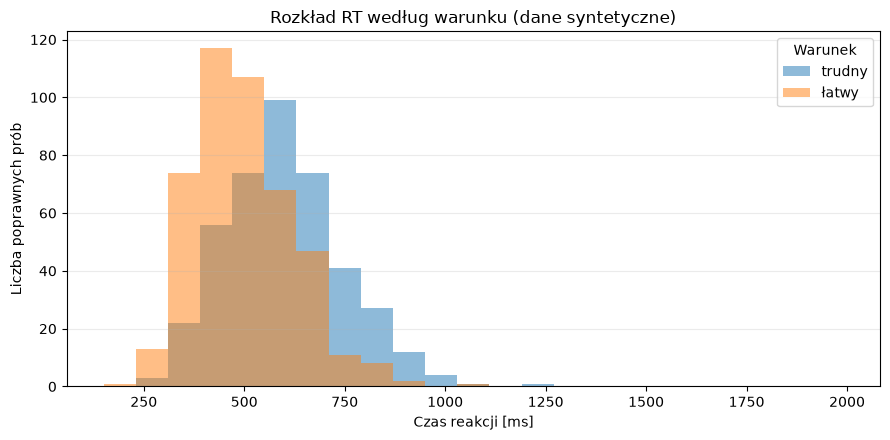

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, group in valid.groupby("condition"):
    ax.hist(group.rt_ms, bins=np.arange(150, 2001, 80), alpha=0.5, label=name)
ax.set(xlabel="Czas reakcji [ms]", ylabel="Liczba poprawnych prób",
       title="Rozkład RT według warunku (dane syntetyczne)")
ax.legend(title="Warunek")
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()


---
## 6. Mediany RT: porównanie wewnątrzosobnicze

Dla każdego uczestnika wyliczamy medianę w warunku łatwym i trudnym. Różnica dodatnia oznacza dłuższą odpowiedź w warunku trudnym. Nie wykonujemy tutaj testu hipotezy (ten temat pojawi się w wykładzie 7).

condition    trudny  łatwy  difference_ms
participant                              
P01           601.7  505.1           96.6
P02           480.5  405.7           74.8
P03           662.2  485.0          177.2
P04           588.8  501.4           87.4
P05           588.0  499.4           88.6
Mediana różnicy [ms]: 97.8


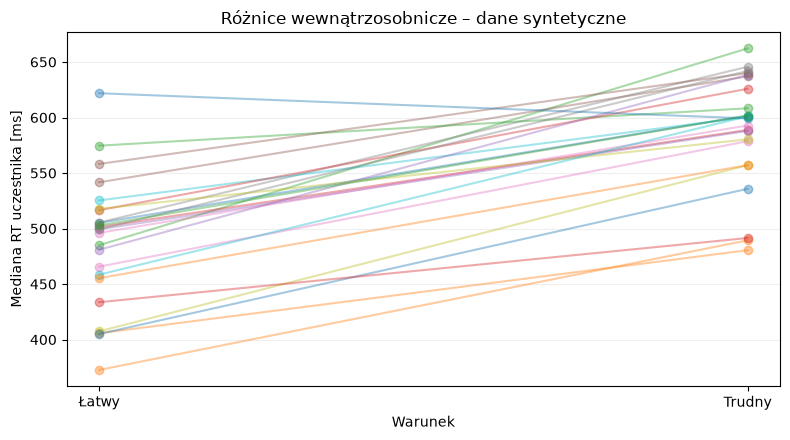

In [7]:
per_person = valid.groupby(["participant", "condition"]).rt_ms.median().unstack()
per_person["difference_ms"] = per_person["trudny"] - per_person["łatwy"]
print(per_person.head().round(1))
print("Mediana różnicy [ms]:", round(per_person.difference_ms.median(), 1))
fig, ax = plt.subplots(figsize=(8, 4.5))
for _, row in per_person.dropna().iterrows():
    ax.plot([0, 1], [row["łatwy"], row["trudny"]], "o-", alpha=.4)
ax.set_xticks([0, 1], ["Łatwy", "Trudny"])
ax.set(xlabel="Warunek", ylabel="Mediana RT uczestnika [ms]",
       title="Różnice wewnątrzosobnicze – dane syntetyczne")
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()


---
## 7. Zapis i odtwarzalność

Odtworzenie wyników: 
**Runtime → Restart and run all** `(Colab)` lub **Kernel → Restart & Run All** `(Jupyter)`

Plik źródłowy pozostaje bez zmian; poniższy komunikat potwierdza zakończenie analizy;

In [8]:
print("Analiza zakończona; pi_w01_data.csv pozostał bez zmian.")


Analiza zakończona; pi_w01_data.csv pozostał bez zmian.


---
## 8. Interpretacja i pytania

1. Czy obserwowana różnica RT jest wytworzona przez model symulacyjny czy zmierzona u ludzi?
2. Dlaczego analiza powinna uwzględniać uczestnika jako jednostkę?
3. Co oznacza brak odpowiedzi i dlaczego nie wpisuje się 0 ms?
4. Jakie inne procesy poza uwagą mogłyby wpływać na czas reakcji?

**Wniosek:** analiza komputerowa może opisywać zachowanie, ale nie upoważnia automatycznie do wnioskowania o konstrukcie psychologicznym (widzimy tylko to co na zewnątrz).

**Literatura:** Yarkoni (2012), DOI 10.1177/0963721412457362; Montag i in. (2016), DOI 10.1155/2016/2983685.